# K-means clustering — Sentinel-2 (unsupervised)
Set `SITE` in Cell 1 ("Shako" or "Subu"), then run all cells in order.

In [1]:
# CELL 1 — SETTINGS + COMBINE ALL DATE-WISE CSVs (labels removed)
import os
import re
import glob
import joblib
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    accuracy_score, cohen_kappa_score, f1_score,
    adjusted_rand_score, normalized_mutual_info_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ---------------------------------------------------
# PROJECT ROOT (folder that contains "Data")
# ---------------------------------------------------
try:
    BASE_DIR
except NameError:
    BASE_DIR = os.getcwd()
    while not os.path.isdir(os.path.join(BASE_DIR, "Data")):
        parent = os.path.dirname(BASE_DIR)
        if parent == BASE_DIR:
            raise FileNotFoundError("Could not find a 'Data' folder above the current directory")
        BASE_DIR = parent

# =====================================================
# SETTINGS
# =====================================================
SITE   = "Shako"          # change to "Subu" for the second lake
SENSOR = "Sentinel2"

RANDOM_STATE = 42
N_CLUSTERS   = 3          # final number of clusters (3 = Glacier, Glacial Lake, Non-Glacier Land)
K_RANGE      = range(2, 9)  # k values tried in the elbow / silhouette test

# Features given to K-means: 4 bands + 2 indices (labels are NOT used for clustering)
FEATURES   = ["Blue", "Green", "Red", "NIR", "NDSI_Value", "NDWI_Value"]
LABEL_COLS = ["Final_Class", "level_numerical"]     # removed before clustering

# Class names / IDs used by all your classified maps (0 = no data)
class_map   = {"Glacier": 1, "Glacial Lake": 2, "Non-Glacier Land": 3}
CLASS_NAMES = list(class_map)

# Sentinel-2 band positions in your files (B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12)
BAND_POS = {"Blue": 1, "Green": 2, "Red": 3, "NIR": 7, "SWIR1": 9}

# =====================================================
# PATHS
# =====================================================
spectral_dir  = os.path.join(BASE_DIR, "Data", SITE, "Data sample", SENSOR, "Sample Levels", "Spectral")
image_dir     = os.path.join(BASE_DIR, "Data", SITE, SENSOR)
model_out_dir = os.path.join(spectral_dir, "models", "output")      # supervised model maps

out_dir  = os.path.join(BASE_DIR, "Data", SITE, "KMeans", SENSOR)
map_dir  = os.path.join(out_dir, "maps")
os.makedirs(map_dir, exist_ok=True)

# Remove old K-means outputs so only the current run remains
for folder in (out_dir, map_dir):
    for pattern in ("*.csv", "*.tif", "*.png", "*.joblib"):
        for old in glob.glob(os.path.join(folder, pattern)):
            os.remove(old)

def extract_date(name):
    m = re.search(r"\d{4}-\d{2}-\d{2}", name)
    return m.group(0) if m else None

# =====================================================
# COMBINE ALL DATE-WISE CSVs
# =====================================================
csv_files = sorted(glob.glob(os.path.join(spectral_dir, f"{SENSOR}_Spectral_Values_*.csv")))
if not csv_files:
    raise FileNotFoundError(f"No spectral CSVs found in {spectral_dir}")

parts = []
for f in csv_files:
    df = pd.read_csv(f)
    df["Date"] = extract_date(os.path.basename(f))
    parts.append(df.dropna(subset=FEATURES))
all_df = pd.concat(parts, ignore_index=True)

# Reference labels kept aside ONLY for the comparison later
reference = all_df["Final_Class"].astype(str).to_numpy()

# Input table for clustering: label columns removed
features_df = all_df.drop(columns=LABEL_COLS)
features_df.to_csv(os.path.join(out_dir, f"KMeans_input_{SENSOR}_{SITE}.csv"), index=False)

print(f"{SITE} | {len(csv_files)} dates combined -> {len(features_df):,} points")
print("Columns given to K-means:", FEATURES)
print("Label columns removed   :", LABEL_COLS)
print("\nPoints per date:")
print(features_df["Date"].value_counts().sort_index().to_string())


Shako | 9 dates combined -> 647,811 points
Columns given to K-means: ['Blue', 'Green', 'Red', 'NIR', 'NDSI_Value', 'NDWI_Value']
Label columns removed   : ['Final_Class', 'level_numerical']

Points per date:
Date
2025-11-14    71980
2025-11-19    71980
2025-11-24    71980
2025-11-29    71978
2025-12-04    71974
2025-12-09    71979
2025-12-14    71980
2025-12-19    71980
2025-12-24    71980


 k     Inertia  Silhouette  Davies_Bouldin
 2 132316.5825      0.6178          0.5746
 3  69947.9104      0.5819          0.6732
 4  51566.6225      0.5992          0.5668
 5  37730.2463      0.5093          0.6249
 6  27523.4207      0.4897          0.6396
 7  22713.5635      0.4749          0.6931
 8  19500.2950      0.4694          0.7356


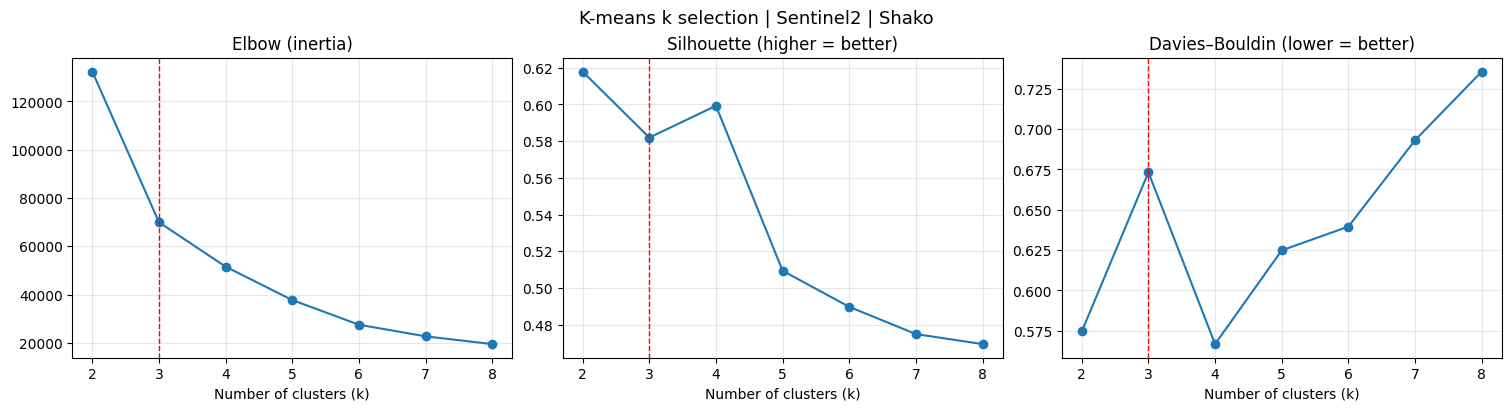

In [2]:
# CELL 2 — SCALE FEATURES + CHOOSE k (elbow, silhouette, Davies–Bouldin)
X = features_df[FEATURES].to_numpy(dtype=float)

scaler   = StandardScaler().fit(X)          # bands (0–10000) and indices (−1…1) on the same scale
X_scaled = scaler.transform(X)

rng = np.random.default_rng(RANDOM_STATE)
idx_fit = rng.choice(len(X_scaled), size=min(60000, len(X_scaled)), replace=False)   # sample for speed
idx_sil = idx_fit[:min(10000, len(idx_fit))]

rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled[idx_fit])
    lab_sil = km.predict(X_scaled[idx_sil])
    rows.append({
        "k": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_scaled[idx_sil], lab_sil),
        "Davies_Bouldin": davies_bouldin_score(X_scaled[idx_sil], lab_sil),
    })
k_table = pd.DataFrame(rows)
k_table.to_csv(os.path.join(out_dir, f"KMeans_k_selection_{SITE}.csv"), index=False)
print(k_table.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
ax[0].plot(k_table.k, k_table.Inertia, "o-");        ax[0].set_title("Elbow (inertia)")
ax[1].plot(k_table.k, k_table.Silhouette, "o-");     ax[1].set_title("Silhouette (higher = better)")
ax[2].plot(k_table.k, k_table.Davies_Bouldin, "o-"); ax[2].set_title("Davies–Bouldin (lower = better)")
for a in ax:
    a.set_xlabel("Number of clusters (k)")
    a.axvline(N_CLUSTERS, color="red", ls="--", lw=1)
    a.grid(alpha=0.3)
fig.suptitle(f"K-means k selection | {SENSOR} | {SITE}", fontsize=13)
fig.savefig(os.path.join(out_dir, f"KMeans_k_selection_{SITE}.png"), dpi=300)
plt.show()


In [3]:
# CELL 3 — FINAL K-MEANS + MATCH CLUSTERS TO CLASS NAMES
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
clusters = kmeans.labels_

# K-means only gives cluster numbers (0, 1, 2 ...). To compare, each cluster is given the
# class it overlaps most with in the reference (Hungarian matching when k <= number of classes,
# majority vote when k > number of classes). The labels are used ONLY for this naming step.
ref_classes = sorted(set(reference))
table = pd.crosstab(pd.Series(clusters, name="Cluster"), pd.Series(reference, name="Reference"))
table = table.reindex(columns=ref_classes, fill_value=0)

if N_CLUSTERS <= len(ref_classes):
    r_idx, c_idx = linear_sum_assignment(-table.to_numpy())
    cluster_to_class = {int(table.index[r]): table.columns[c] for r, c in zip(r_idx, c_idx)}
else:
    cluster_to_class = {int(c): table.loc[c].idxmax() for c in table.index}

kmeans_class = np.array([cluster_to_class[int(c)] for c in clusters])

print("Cluster vs reference (point counts):")
print(table.to_string())
print("\nCluster -> class:", cluster_to_class)

# Cluster profile (mean feature values) — useful table for the paper
profile = features_df[FEATURES].assign(Cluster=clusters).groupby("Cluster").mean()
profile["Assigned_Class"] = [cluster_to_class[int(c)] for c in profile.index]
profile["Points"] = pd.Series(clusters).value_counts().sort_index().to_numpy()
print("\nCluster profile (mean values):")
print(profile.round(4).to_string())
profile.to_csv(os.path.join(out_dir, f"KMeans_cluster_profile_{SITE}.csv"))

# Save clustered points and the fitted model
clustered = features_df.copy()
clustered["Cluster"] = clusters
clustered["KMeans_Class"] = kmeans_class
clustered["Reference_Class"] = reference          # added back only for comparison
clustered.to_csv(os.path.join(out_dir, f"KMeans_clustered_points_{SITE}.csv"), index=False)

joblib.dump({"scaler": scaler, "kmeans": kmeans, "features": FEATURES,
             "cluster_to_class": cluster_to_class},
            os.path.join(out_dir, f"KMeans_model_{SITE}.joblib"))
print(f"\n💾 Saved clustered points + model in {out_dir}")


Cluster vs reference (point counts):
Reference  Glacial Lake  Glacier  Non-Glacier Land
Cluster                                           
0                     0       10            370914
1                     0   110551               524
2                 13089    89361             63362

Cluster -> class: {0: 'Non-Glacier Land', 1: 'Glacier', 2: 'Glacial Lake'}

Cluster profile (mean values):
              Blue      Green        Red        NIR  NDSI_Value  NDWI_Value    Assigned_Class  Points
Cluster                                                                                              
0         751.5279   929.6287  1124.3464  1526.9322     -0.4698     -0.2618  Non-Glacier Land  370924
1        8527.3264  8357.5294  8073.4849  7194.4213      0.8236      0.0754           Glacier  111075
2        3200.7713  3095.2802  2920.7417  2676.8497      0.4833      0.1400      Glacial Lake  165812

💾 Saved clustered points + model in c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GL

K-means vs reference labels (NDSI/NDWI threshold classes)
      Date  Points    OA_%  Kappa  Macro_F1    ARI    NMI
 ALL DATES  647811 76.3423 0.5757    0.5927 0.6116 0.5635
2025-11-14   71980 76.3657 0.6107    0.6167 0.5915 0.5765
2025-11-19   71980 76.4407 0.5993    0.6082 0.6037 0.5739
2025-11-24   71980 76.0517 0.5866    0.6025 0.5993 0.5650
2025-11-29   71978 76.3567 0.5812    0.5963 0.6135 0.5673
2025-12-04   71974 76.4095 0.5718    0.5909 0.6196 0.5646
2025-12-09   71979 77.0933 0.5706    0.5882 0.6328 0.5673
2025-12-14   71980 74.5804 0.5296    0.5592 0.5635 0.5279
2025-12-19   71980 76.9783 0.5531    0.5763 0.6357 0.5615
2025-12-24   71980 76.8047 0.5436    0.5689 0.6382 0.5593

Class-wise report (all dates):
                  precision    recall  f1-score   support

    Glacial Lake     0.0789    1.0000    0.1463     13089
         Glacier     0.9953    0.5530    0.7109    199922
Non-Glacier Land     1.0000    0.8531    0.9207    434800

        accuracy                      

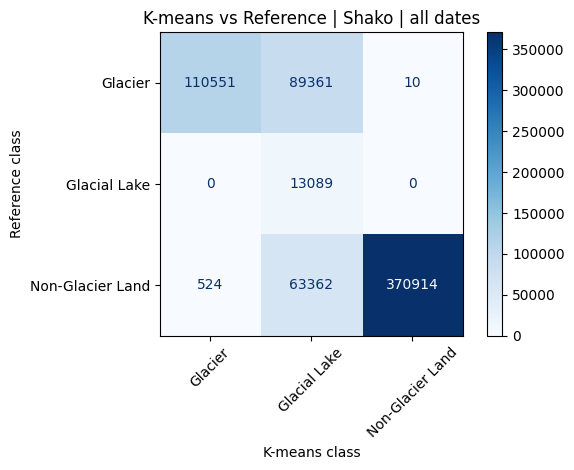

In [4]:
# CELL 4 — COMPARE K-MEANS WITH THE REFERENCE LABELS (sample points)
def scores(ref, pred, ref_clusters=None):
    out = {
        "Points": len(ref),
        "OA_%": 100 * accuracy_score(ref, pred),
        "Kappa": cohen_kappa_score(ref, pred),
        "Macro_F1": f1_score(ref, pred, average="macro", zero_division=0),
    }
    if ref_clusters is not None:                       # mapping-free cluster agreement
        out["ARI"] = adjusted_rand_score(ref, ref_clusters)
        out["NMI"] = normalized_mutual_info_score(ref, ref_clusters)
    return out

rows = [{"Date": "ALL DATES", **scores(reference, kmeans_class, clusters)}]
for d in sorted(clustered["Date"].unique()):
    m = (clustered["Date"] == d).to_numpy()
    rows.append({"Date": d, **scores(reference[m], kmeans_class[m], clusters[m])})
ref_metrics = pd.DataFrame(rows)
ref_metrics.to_csv(os.path.join(out_dir, f"KMeans_vs_Reference_{SITE}.csv"), index=False)

print("K-means vs reference labels (NDSI/NDWI threshold classes)")
print(ref_metrics.round(4).to_string(index=False))
print("\nClass-wise report (all dates):")
print(classification_report(reference, kmeans_class, digits=4, zero_division=0))

labels = [c for c in CLASS_NAMES if c in set(reference) | set(kmeans_class)]
cm = confusion_matrix(reference, kmeans_class, labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title(f"K-means vs Reference | {SITE} | all dates")
plt.ylabel("Reference class"); plt.xlabel("K-means class")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, f"KMeans_confusion_vs_Reference_{SITE}.png"), dpi=300)
plt.show()


In [5]:
# CELL 5 — FULL-IMAGE K-MEANS MAPS + COMPARE WITH THE SUPERVISED MODEL MAPS
# where each supervised model saved its maps (models that were not run are skipped)
model_maps = {
    "Decision Tree": lambda d: os.path.join(model_out_dir, f"classified_{SENSOR}_{d}.tif"),
    "Random Forest": lambda d: os.path.join(model_out_dir, "random_forest", f"classified_{SENSOR}_random_forest_{d}.tif"),
    "XGBoost":       lambda d: os.path.join(model_out_dir, "xgboost",       f"classified_{SENSOR}_xgboost_{d}.tif"),
    "ANN":           lambda d: os.path.join(model_out_dir, "ann",           f"classified_{SENSOR}_ann_{d}.tif"),
    "CNN":           lambda d: os.path.join(model_out_dir, "cnn",           f"classified_{SENSOR}_cnn_{d}.tif"),
}
lut = np.zeros(N_CLUSTERS, dtype=np.uint8)
for c, name in cluster_to_class.items():
    lut[c] = class_map[name]

image_files = sorted(glob.glob(os.path.join(image_dir, "*.tif")))
model_rows = []

for img in image_files:
    d = extract_date(os.path.basename(img))
    if d is None:
        continue

    # ---- same 6 features as in the CSVs, computed for every pixel ----
    with rasterio.open(img) as src:
        b = {k: src.read(v).astype(np.float32) for k, v in BAND_POS.items()}
        profile_tif = src.profile
    nodata = (b["Blue"] == 0) & (b["Green"] == 0) & (b["Red"] == 0) & (b["NIR"] == 0)
    ndsi = (b["Green"] - b["SWIR1"]) / (b["Green"] + b["SWIR1"] + 1e-10)
    ndwi = (b["Green"] - b["NIR"])   / (b["Green"] + b["NIR"]   + 1e-10)
    feat = {"Blue": b["Blue"], "Green": b["Green"], "Red": b["Red"], "NIR": b["NIR"],
            "NDSI_Value": ndsi, "NDWI_Value": ndwi}
    pix = np.stack([feat[f].ravel() for f in FEATURES], axis=1).astype(np.float64)   # same dtype as training

    km_map = lut[kmeans.predict(scaler.transform(pix))].reshape(nodata.shape)
    km_map[nodata] = 0

    profile_tif.update(dtype=rasterio.uint8, count=1, nodata=0, compress="lzw")
    with rasterio.open(os.path.join(map_dir, f"KMeans_{SENSOR}_{d}.tif"), "w", **profile_tif) as dst:
        dst.write(km_map, 1)

    # ---- pixel-by-pixel agreement with each supervised model map ----
    for model_name, path_of in model_maps.items():
        p = path_of(d)
        if not os.path.exists(p):
            continue
        with rasterio.open(p) as src:
            sup = src.read(1)
        if sup.shape != km_map.shape:
            print(f"⚠ {model_name} {d}: map size {sup.shape} differs from image {km_map.shape}, skipped")
            continue
        valid = (sup > 0) & (km_map > 0)
        model_rows.append({"Model": model_name, "Date": d, **scores(sup[valid], km_map[valid])})

    print(f"✅ {d}: K-means map saved")

model_metrics = pd.DataFrame(model_rows)
if model_metrics.empty:
    print("\n⚠ No supervised model maps found to compare with")
else:
    model_metrics.to_csv(os.path.join(out_dir, f"KMeans_vs_Models_{SITE}.csv"), index=False)
    summary = model_metrics.groupby("Model")[["OA_%", "Kappa", "Macro_F1"]].mean()
    summary = summary.reindex([m for m in model_maps if m in summary.index])
    summary.to_csv(os.path.join(out_dir, f"KMeans_vs_Models_summary_{SITE}.csv"))
    print("\nK-means agreement with each supervised model (all pixels, mean over dates):")
    print(summary.round(4).to_string())
    print("\nOverall agreement (%) per date:")
    print(model_metrics.pivot(index="Date", columns="Model", values="OA_%")
                       .reindex(columns=summary.index).round(2).to_string())


✅ 2025-11-14: K-means map saved
✅ 2025-11-19: K-means map saved
✅ 2025-11-24: K-means map saved
✅ 2025-11-29: K-means map saved
✅ 2025-12-04: K-means map saved
✅ 2025-12-09: K-means map saved
✅ 2025-12-14: K-means map saved
✅ 2025-12-19: K-means map saved
✅ 2025-12-24: K-means map saved

K-means agreement with each supervised model (all pixels, mean over dates):
                  OA_%   Kappa  Macro_F1
Model                                   
Decision Tree  76.1857  0.5698    0.5888

Overall agreement (%) per date:
Model       Decision Tree
Date                     
2025-11-14          76.29
2025-11-19          76.28
2025-11-24          75.86
2025-11-29          76.34
2025-12-04          76.16
2025-12-09          76.89
2025-12-14          74.46
2025-12-19          76.74
2025-12-24          76.65


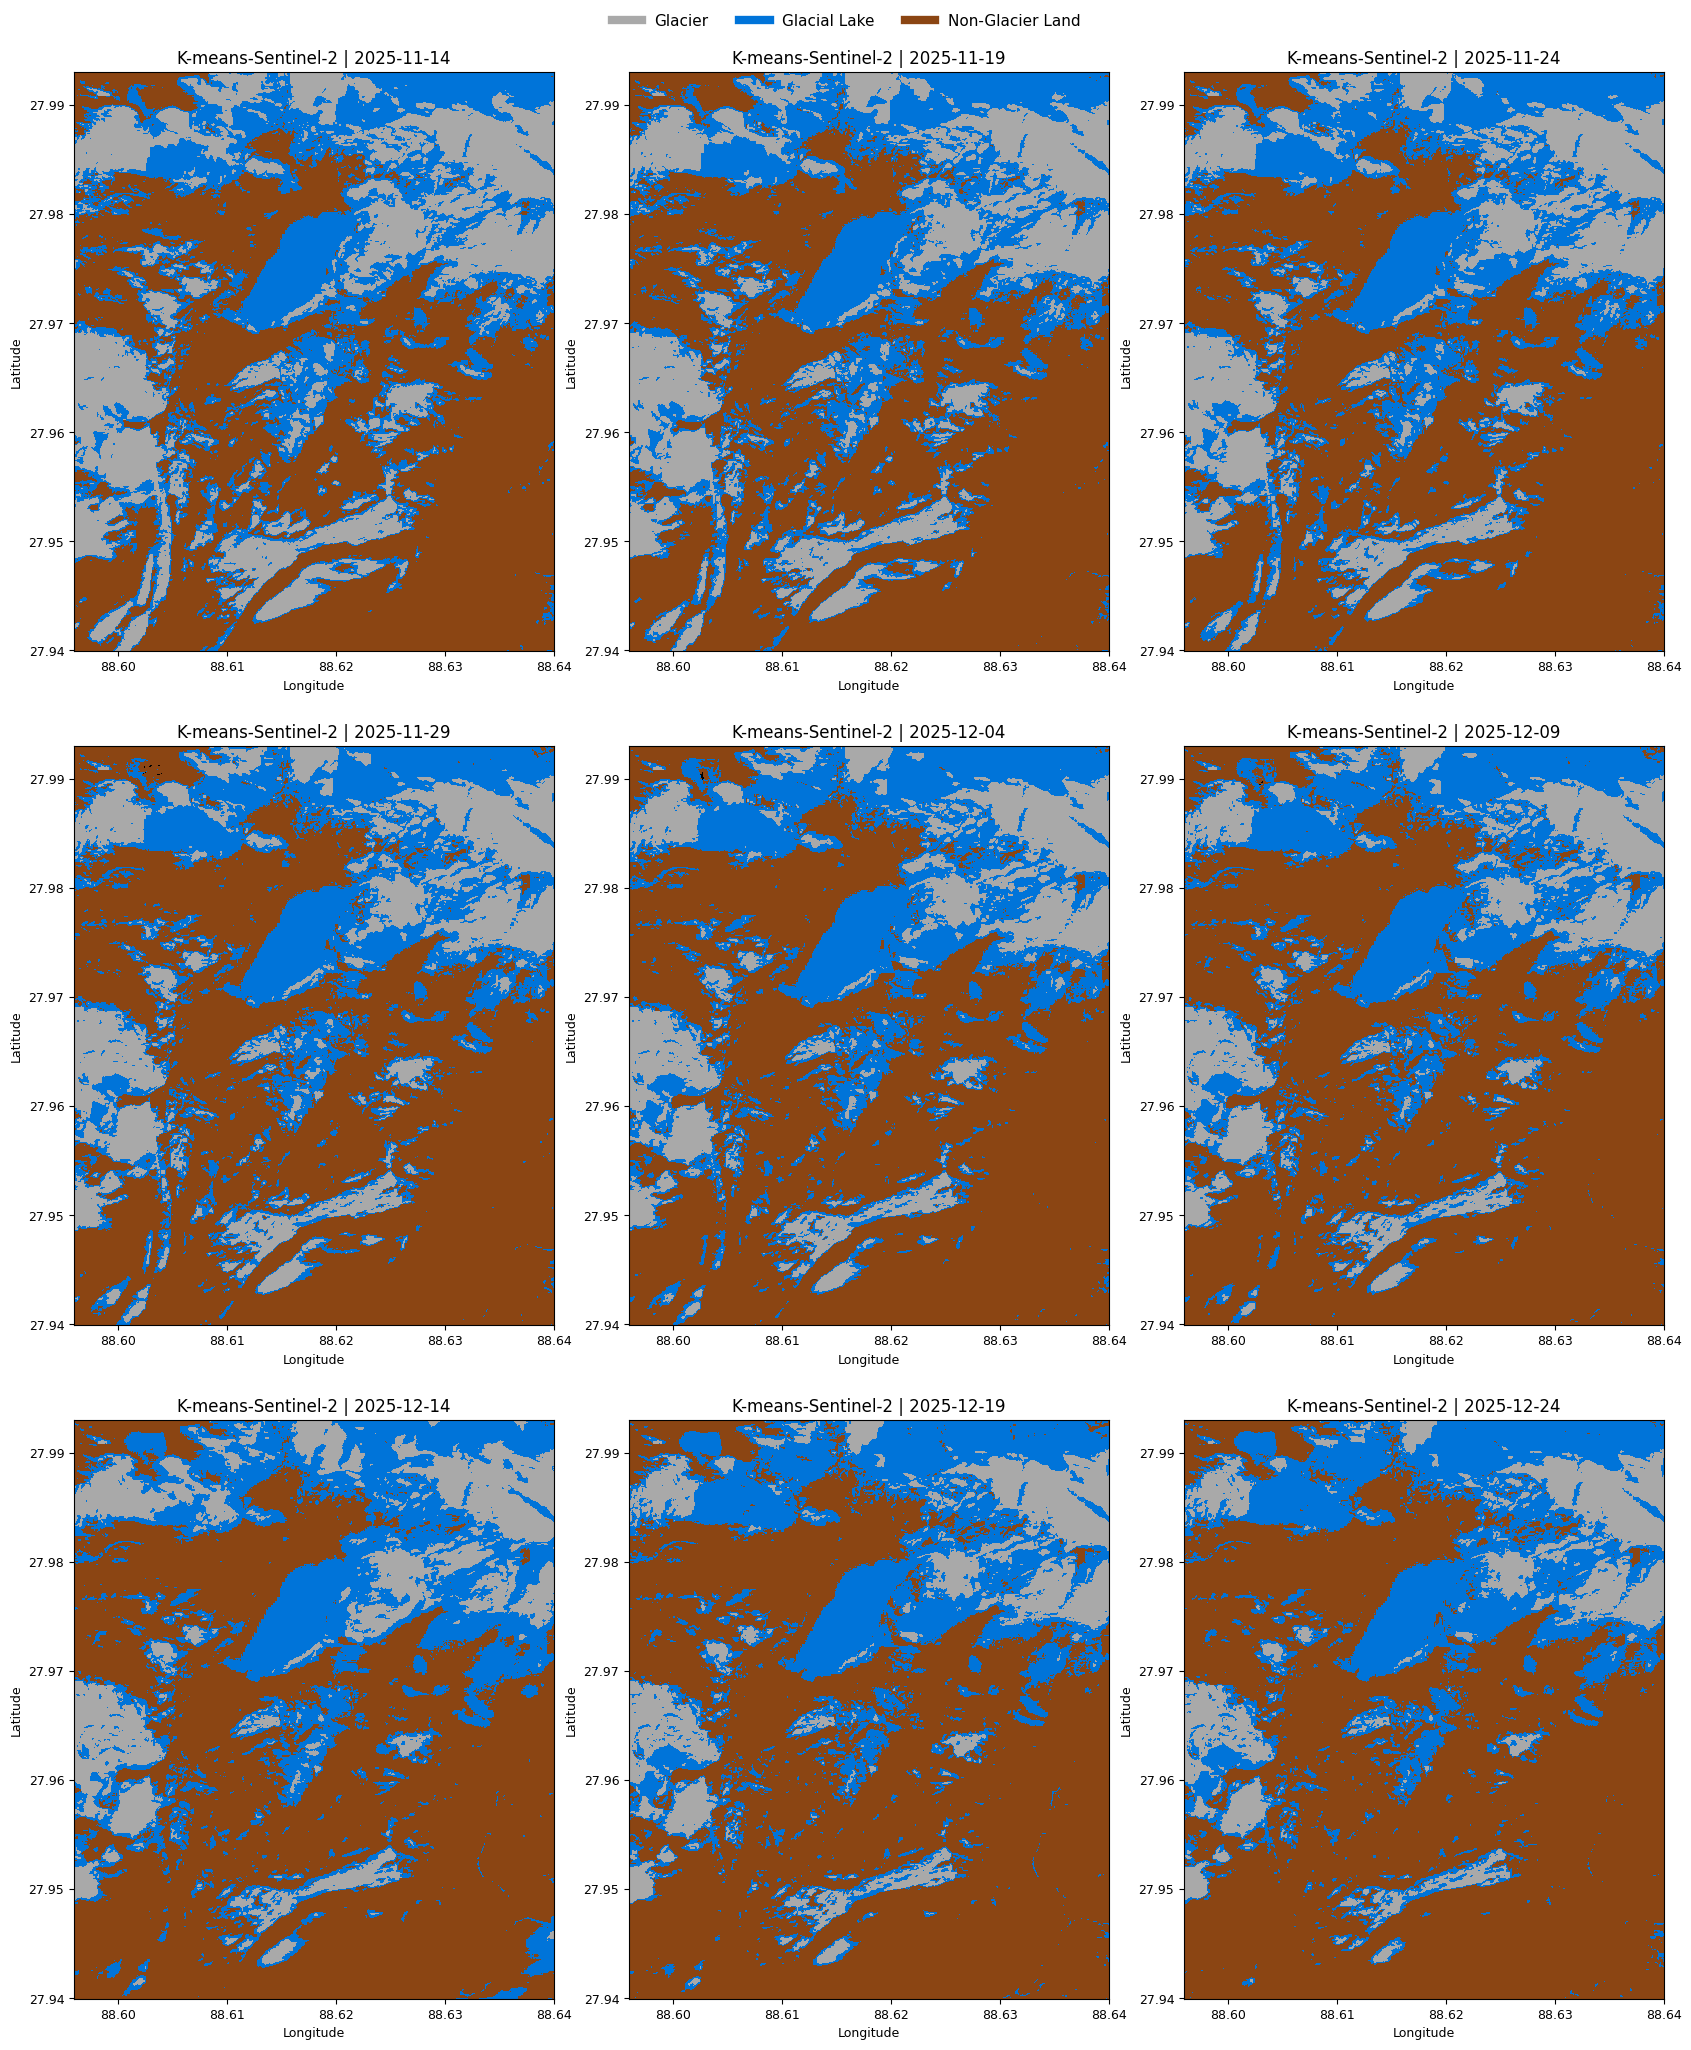

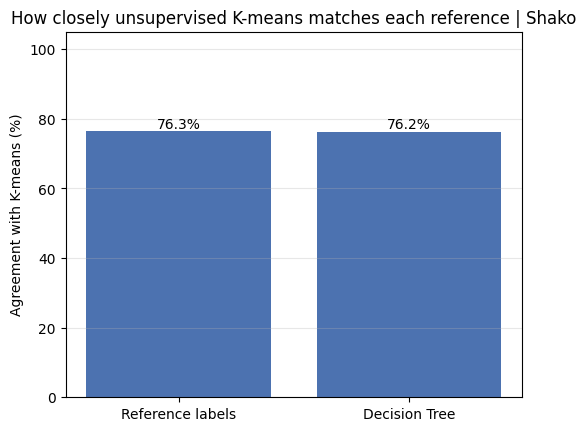


🎉 K-means done for Shako. All outputs in: c:\Users\hp\Downloads\CTECH\Research\proposal\NIDM\GLOF project\Data\Shako\KMeans\Sentinel2


In [6]:
# CELL 6 — PLOTS: K-MEANS MAPS + AGREEMENT CHART
import math
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

km_files = sorted(glob.glob(os.path.join(map_dir, "*.tif")))
n = len(km_files)
cols = 3
rows_ = math.ceil(n / cols)

with rasterio.open(km_files[0]) as s0:
    b0 = s0.bounds
panel_w = 4.8
panel_h = panel_w * (b0.top - b0.bottom) / (b0.right - b0.left)
gap_w, gap_h, left_in, right_in, top_in, bottom_in = 0.75, 0.95, 0.75, 0.20, 0.70, 0.60
fig_w = left_in + cols * panel_w + (cols - 1) * gap_w + right_in
fig_h = top_in + rows_ * panel_h + (rows_ - 1) * gap_h + bottom_in

fig, axes = plt.subplots(rows_, cols, figsize=(fig_w, fig_h), squeeze=False)
axes = axes.flatten()
plt.subplots_adjust(left=left_in / fig_w, right=1 - right_in / fig_w,
                    bottom=bottom_in / fig_h, top=1 - top_in / fig_h,
                    wspace=gap_w / panel_w, hspace=gap_h / panel_h)

cmap = ListedColormap(["black", "#A9A9A9", "#0074D9", "#8B4513"])   # 0 no data, 1, 2, 3
norm = BoundaryNorm([0, 1, 2, 3, 4], cmap.N)

for i, f in enumerate(km_files):
    with rasterio.open(f) as src:
        arr, bd = src.read(1), src.bounds
    ax = axes[i]
    ax.imshow(arr, cmap=cmap, norm=norm, extent=[bd.left, bd.right, bd.bottom, bd.top],
              interpolation="nearest")
    ax.set_title(f"K-means-Sentinel-2 | {extract_date(os.path.basename(f))}", fontsize=12)
    ax.set_xlabel("Longitude", fontsize=9); ax.set_ylabel("Latitude", fontsize=9)
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5)); ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.tick_params(labelsize=9)
for j in range(n, len(axes)):
    axes[j].axis("off")

fig.legend(handles=[Line2D([0], [0], color=c, lw=6, label=l) for c, l in
                    zip(["#A9A9A9", "#0074D9", "#8B4513"], CLASS_NAMES)],
           loc="upper center", ncol=3, frameon=False, fontsize=11)
fig.savefig(os.path.join(out_dir, f"KMeans_maps_{SITE}.png"), dpi=300)
plt.show()

# ---- agreement chart: reference + every supervised model ----
bars = {"Reference labels": ref_metrics.loc[0, "OA_%"]}
if not model_metrics.empty:
    bars.update(summary["OA_%"].to_dict())
fig, ax = plt.subplots(figsize=(1.6 * len(bars) + 2, 4.2), constrained_layout=True)
ax.bar(list(bars), list(bars.values()), color="#4C72B0")
for x, v in enumerate(bars.values()):
    ax.text(x, v + 1, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylim(0, 105)
ax.set_ylabel("Agreement with K-means (%)")
ax.set_title(f"How closely unsupervised K-means matches each reference | {SITE}")
ax.grid(axis="y", alpha=0.3)
fig.savefig(os.path.join(out_dir, f"KMeans_agreement_{SITE}.png"), dpi=300)
plt.show()

print(f"\n🎉 K-means done for {SITE}. All outputs in: {out_dir}")
